# Maternal Health Risk Classification Using Machine Learning

### 1. Introduction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Maternal Health Risk Data Set.csv')

In [3]:
df.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [4]:
df.shape

(1014, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


In [6]:
df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


### 2. Data Cleaning

In [7]:
df.isnull().sum()

Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

In [8]:
df.duplicated().sum()

562

In [9]:
df[df.duplicated(keep=False)].head(10)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
1,35,140,90,13.00,98.0,70,high risk
2,29,90,70,8.00,100.0,80,high risk
3,30,140,85,7.00,98.0,70,high risk
4,35,120,60,6.10,98.0,76,low risk
5,23,140,80,7.01,98.0,70,high risk
6,23,130,70,7.01,98.0,78,mid risk
7,35,85,60,11.00,102.0,86,high risk
8,32,120,90,6.90,98.0,70,mid risk
9,42,130,80,18.00,98.0,70,high risk
11,19,120,80,7.00,98.0,70,mid risk


In [10]:
df["RiskLevel"].value_counts()

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

In [11]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Check the result
print(df.shape)
print(df.duplicated().sum())

(452, 7)
0


In [12]:
df["RiskLevel"].value_counts()

RiskLevel
low risk     234
high risk    112
mid risk     106
Name: count, dtype: int64

## 3. Exploratory Data Analysis (EDA)

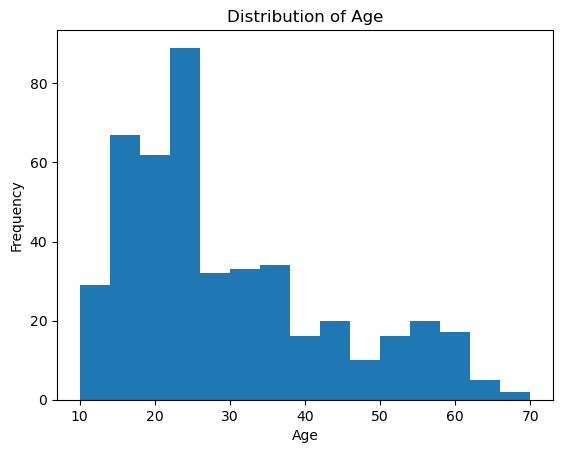

In [14]:
plt.hist(df['Age'], bins = 15)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

### The histogram shows that most individuals are between 15 and 30 years old. The number of observations generally decreases as age increases. The distribution is right-skewed.

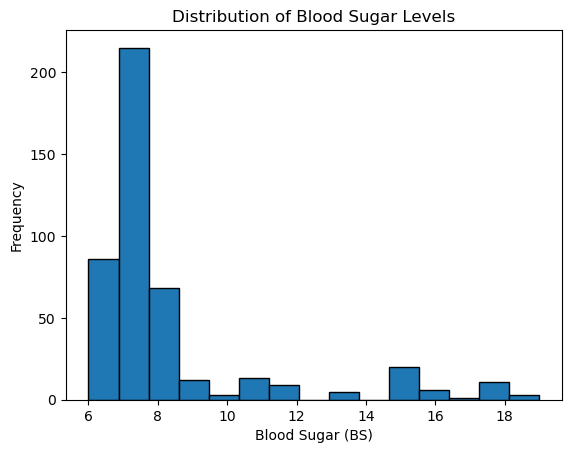

In [15]:
# Check the distribution of blood sugar levels
plt.hist(df['BS'], bins = 15, edgecolor = 'black')
plt.title('Distribution of Blood Sugar Levels')
plt.xlabel('Blood Sugar (BS)')
plt.ylabel('Frequency')
plt.show()

### Most blood sugar values are concentrated around 7–8. Higher values are less common, and the distribution is right-skewed.

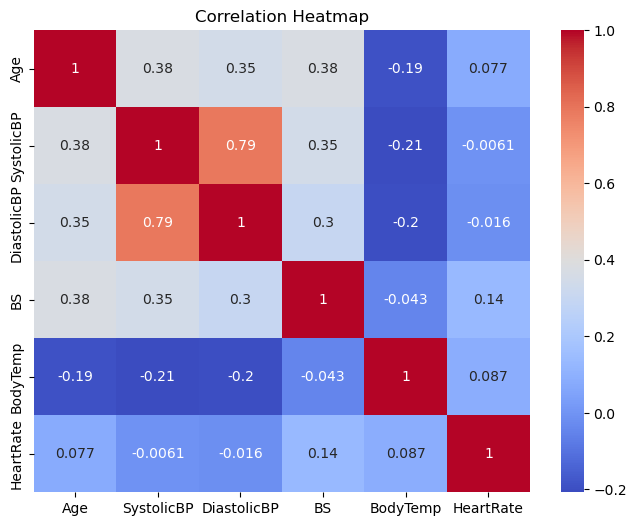

In [16]:
# Check correlations between numerical features
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### SystolicBP and DiastolicBP have a strong positive correlation (0.79). Age has a moderate positive correlation with blood sugar (0.38). Most other variables show weak or moderate correlations.

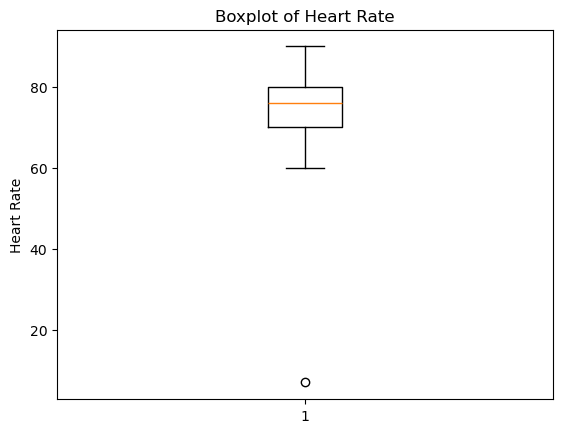

In [17]:
# Check possible outliers in heart rate
plt.boxplot(df['HeartRate'])
plt.title('Boxplot of Heart Rate')
plt.ylabel('Heart Rate')
plt.show()

### Most heart rate values are between 70 and 80 bpm. One unusually low value of 7 bpm appears as an outlier and needs further checking.

In [18]:
# Check records with an unusually low heart rate
df[df['HeartRate'] == 7]

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
342,16,120,75,7.9,98.0,7,low risk


In [19]:
# Count unusually low heart rate values
df[df['HeartRate'] == 7].shape[0]

1

In [20]:
# Remove the unrealistic heart rate value
df = df[df['HeartRate'] != 7].reset_index(drop=True)

# Check the dataset size
df.shape

(451, 7)

#### One unusually low heart rate value (7 bpm) was identified. It was removed as a likely data entry error.

## 4. Machine Learning Model Development

In [21]:
# Select input features (X) and target variable (y)
X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

# Check the size of X and y
print("Features:", X.shape)
print("Target:", y.shape)

Features: (451, 6)
Target: (451,)


In [22]:
# Display the first five rows of features
X.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
0,25,130,80,15.0,98.0,86
1,35,140,90,13.0,98.0,70
2,29,90,70,8.0,100.0,80
3,30,140,85,7.0,98.0,70
4,35,120,60,6.1,98.0,76


In [23]:
# Display the first five target values
y.head()

0    high risk
1    high risk
2    high risk
3    high risk
4     low risk
Name: RiskLevel, dtype: object

In [24]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42)

# Check the size of training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (428, 6)
Testing features: (23, 6)
Training target: (428,)
Testing target: (23,)
